# Chapter 11 · Probability: companion notebook
*Data Science and Artificial Intelligence in Health, Volume 1*

> **This notebook accompanies the book chapter; it does not reproduce it.** Definitions, derivations, and explanations are in the book. Here you run the calculations on the case and check the numbers. All data are **synthetic**, and the values are for teaching purposes only; they have no correlation with the real world.

**Part A** follows the chapter's case, the delivery register of a public maternity unit, through the committee's six questions. **Part B** gives the code and result of each of the twelve chapter exercises (statements are in the book). Run the cells in order.

## Part A. The case

**Data.** `data/deliveries.csv`: 5,000 rows, one per delivery, and four columns: `delivery_id`, `cesarean`, `hemorrhage`, `infection` (yes/no). The six sections below follow the committee's questions, in the order of the chapter.

The first five rows of the register:

In [1]:
import pandas as pd

register = pd.read_csv("data/deliveries.csv")
rows, columns = register.shape
print(f"The register has {rows:,} rows (one per delivery) and {columns} columns.")
register.head()

The register has 5,000 rows (one per delivery) and 4 columns.


,delivery_id,cesarean,hemorrhage,infection
0,D0001,no,no,no
1,D0002,no,no,no
2,D0003,yes,no,no
3,D0004,no,no,no
4,D0005,yes,no,no


### Q1. What fraction of deliveries were cesarean, and what fraction had a hemorrhage?

Deliveries in the register: 5,000
cesarean
no     3687
yes    1313 

cesarean    1,313 of 5,000 deliveries = 26.26%
hemorrhage    290 of 5,000 deliveries = 5.80%

 rows read  cesareans so far  fraction
        10                 5    0.5000
        50                19    0.3800
       100                27    0.2700
       500               123    0.2460
      1000               246    0.2460
      5000              1313    0.2626


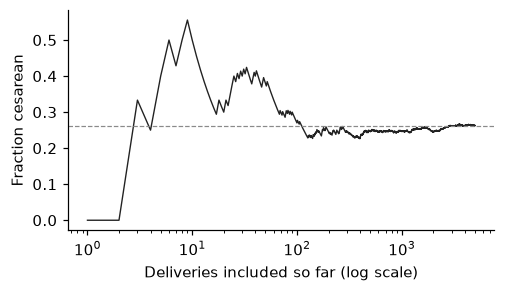

In [2]:
import pandas as pd

df = pd.read_csv("data/deliveries.csv")

# 1. Take all the rows: one row is one delivery
n = len(df)
print(f"Deliveries in the register: {n:,}")

# 2. In each row, look at the column: is it "yes"?
C = df["cesarean"] == "yes"
H = df["hemorrhage"] == "yes"
I = df["infection"] == "yes"
print(df["cesarean"].value_counts().to_string(), "\n")

# 3. Count the "yes" rows and divide by all the rows
for name, event in (("cesarean", C), ("hemorrhage", H)):
    count = int(event.sum())
    print(f"{name:<11} {count:>5,} of {n:,} deliveries = {count / n:.2%}")

# 4. Read the register in order: does the fraction of cesareans settle?
running = C.cumsum() / range(1, n + 1)   # cesareans so far / rows read so far
checkpoints = [10, 50, 100, 500, 1000, 5000]
print()
print(pd.DataFrame({"rows read": checkpoints,
                    "cesareans so far": [int(C.iloc[:k].sum()) for k in checkpoints],
                    "fraction": [round(running.iloc[k - 1], 4) for k in checkpoints]}).to_string(index=False))

import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(range(1, n + 1), running, color="#222222", linewidth=.9)
ax.axhline(C.mean(), color="#8a8a8a", linewidth=.8, linestyle="--")
ax.set(xscale="log", xlabel="Deliveries included so far (log scale)", ylabel="Fraction cesarean")
plt.show()

### Q2. How many mothers had a hemorrhage or an infection?

In [3]:
# 1. Cross the two columns: each delivery falls in exactly one of four cells
print(pd.crosstab(df["hemorrhage"], df["infection"], margins=True, margins_name="Total"), "\n")

# 2. Add the two groups, then correct for the mothers counted twice
hemorrhage, infection, both = int(H.sum()), int(I.sum()), int((H & I).sum())
print(f"Hemorrhage:               {hemorrhage:>4}")
print(f"Infection:                {infection:>4}")
print(f"Adding the two:           {hemorrhage + infection:>4}   (the {both} mothers with both are counted twice)")
print(f"Both:                     {both:>4}")
print(f"Hemorrhage or infection:  {hemorrhage + infection - both:>4}   = {hemorrhage} + {infection} - {both}\n")

# 3. Check by counting directly, and count the mothers with neither
either = H | I                           # True when the row has at least one of the two
print(f"Counted directly:  {int(either.sum())} of {n:,} = {either.mean():.2%}")
print(f"With neither:      {int((~either).sum()):,} of {n:,} = {(~either).mean():.2%}")

infection     no  yes  Total
hemorrhage                  
no          4599  111   4710
yes          271   19    290
Total       4870  130   5000 

Hemorrhage:                290
Infection:                 130
Adding the two:            420   (the 19 mothers with both are counted twice)
Both:                       19
Hemorrhage or infection:   401   = 290 + 130 - 19

Counted directly:  401 of 5,000 = 8.02%
With neither:      4,599 of 5,000 = 91.98%


### Q3. Is infection more frequent after a cesarean?

In [4]:
# 1. Split the deliveries by type: cesarean, and vaginal (not cesarean)
groups = {"cesarean": C, "vaginal": ~C}

# 2. Within each group, count the infections and divide by the size of that group
for name, group in groups.items():
    infected, size = int((group & I).sum()), int(group.sum())
    print(f"Infection among {name:<9} {infected:>3} of {size:>5,} = {infected / size:.4f}")

# 3. The same 87 infected cesareans over ALL deliveries (a different denominator)
print(f"Cesarean and infection, among all deliveries: {int((C & I).sum())} of {n:,} = {(C & I).mean():.4f}")

# 4. Infection over all deliveries, whatever the delivery type
print(f"Infection, among all deliveries:              {int(I.sum())} of {n:,} = {I.mean():.4f}")

Infection among cesarean   87 of 1,313 = 0.0663
Infection among vaginal    43 of 3,687 = 0.0117
Cesarean and infection, among all deliveries: 87 of 5,000 = 0.0174
Infection, among all deliveries:              130 of 5,000 = 0.0260


### Q4. Do hemorrhage and infection come together or independently?

In [5]:
# 1. If hemorrhage and infection were independent, P(H and I) would equal P(H) x P(I)
expected = H.mean() * I.mean()
print(f"Expected under independence: {H.mean():.4f} x {I.mean():.4f} = {expected:.6f}")

# 2. What the register shows
print(f"Observed, both together:     {int((H & I).sum())} of {n:,} = {(H & I).mean():.4f}")

# 3. Infection within the mothers with and without hemorrhage
print(f"Infection among hemorrhage:    {int((H & I).sum())} of {int(H.sum())} = {I[H].mean():.4f}")
print(f"Infection among no hemorrhage: {int((~H & I).sum())} of {int((~H).sum()):,} = {I[~H].mean():.4f}\n")

# 4. Multiplying while keeping the conditions: cesarean, then hemorrhage, then infection
print(f"Cesareans: {int(C.sum()):,} | with hemorrhage: {int((C & H).sum())} | with infection too: {int((C & H & I).sum())}")
chain = C.mean() * H[C].mean() * I[C & H].mean()
print(f"P(C) x P(H|C) x P(I|C and H) = {chain:.4f}   (direct count: {(C & H & I).mean():.4f})")

Expected under independence: 0.0580 x 0.0260 = 0.001508
Observed, both together:     19 of 5,000 = 0.0038
Infection among hemorrhage:    19 of 290 = 0.0655
Infection among no hemorrhage: 111 of 4,710 = 0.0236

Cesareans: 1,313 | with hemorrhage: 95 | with infection too: 14
P(C) x P(H|C) x P(I|C and H) = 0.0028   (direct count: 0.0028)


### Q5. Among the mothers with infection, what fraction had a cesarean?

In [6]:
# 1. The table: rows are the delivery type, columns are infection
print(pd.crosstab(df["cesarean"], df["infection"], margins=True, margins_name="Total"), "\n")

# 2. Rebuild the overall infection fraction from the two groups
p_i = I[C].mean() * C.mean() + I[~C].mean() * (~C).mean()
print(f"P(I) = P(I|C) P(C) + P(I|not C) P(not C) = {p_i:.4f}")

# 3. Reverse the condition (Bayes): from infection among cesareans to cesareans among infections
p_c_given_i = I[C].mean() * C.mean() / p_i
print(f"P(C|I) = P(I|C) P(C) / P(I) = {p_c_given_i:.4f}")

# 4. Check by counting directly among the infected mothers
print(f"Counting directly: {int((C & I).sum())} of {int(I.sum())} = {C[I].mean():.4f}  ({C[I].mean():.1%})")

infection    no  yes  Total
cesarean                   
no         3644   43   3687
yes        1226   87   1313
Total      4870  130   5000 

P(I) = P(I|C) P(C) + P(I|not C) P(not C) = 0.0260
P(C|I) = P(I|C) P(C) / P(I) = 0.6692
Counting directly: 87 of 130 = 0.6692  (66.9%)


### Q6. In how many ways can 20 charts be chosen, and how likely is the sample to include an infection?

In [7]:
from math import comb, factorial, perm

N, K = n, int(I.sum())        # N charts in the register, K of them with infection

# 1. In how many ways can 20 charts be chosen? (order does not matter)
sets = comb(N, 20)
print(f"Sets of 20 charts: {sets}  ({len(str(sets))} digits)")

# 2. Orders of the 20 selected charts, and of the first two slots
print(f"Orders of the 20 charts: {factorial(20):,}   First two slots: {perm(20, 2)}")

# 3. Chance of at least one infection = 1 - chance of none (all 20 from the N - K without infection)
def p_at_least_one(m):
    return 1 - comb(N - K, m) / comb(N, m)
print(f"At least one infection in 20 charts: {p_at_least_one(20):.4f}")

# 4. Smallest sample with at least 90% (integer test: no infection is at most 1/10 of all sets)
m = next(m for m in range(1, N + 1) if 10 * comb(N - K, m) <= comb(N, m))
for size in (m - 1, m):
    print(f"{size} charts: {p_at_least_one(size):.6f}")

Sets of 20 charts: 37735558620382470911680923426535607627307325009655406000  (56 digits)
Orders of the 20 charts: 2,432,902,008,176,640,000   First two slots: 380
At least one infection in 20 charts: 0.4102
86 charts: 0.898259
87 charts: 0.900950


## Part B. Exercise solutions

### Exercise 1. Records and event descriptions

In [8]:
from itertools import product

# 1. The sample space: one of the 5,000 identifiers
print(n, df["delivery_id"].nunique())

# 2. The eight descriptions (C, H, I), 1 = yes and 0 = no
print(" ".join("".join(map(str, bits)) for bits in product((0, 1), repeat=3)))

5000 5000
000 001 010 011 100 101 110 111


### Exercise 2. Running fractions and order

In [9]:
# 1. Fraction of cesareans among the first k records
for k in (10, 50, 100, 500, 1000, 5000):
    print(k, f"{C.iloc[:k].mean():.4f}")

# 2. Reverse the register order: first 100 records, and all 5,000
reverse = C.iloc[::-1]
print(f"{reverse.iloc[:100].mean():.4f}", f"{reverse.mean():.4f}")

10 0.5000
50 0.3800
100 0.2700
500 0.2460
1000 0.2460
5000 0.2626
0.2500 0.2626


### Exercise 3. Count the overlap once

In [10]:
# 1. The four groups: hemorrhage only, infection only, both, neither
for group in (H & ~I, ~H & I, H & I, ~(H | I)):
    print(int(group.sum()), f"{group.mean():.4f}")

# 2. Addition rule, and the same count done directly
union = H.sum() + I.sum() - (H & I).sum()
print(int(union), f"{union / n:.4f}")
print(int((H | I).sum()), f"{1 - (H | I).mean():.4f}")

271 0.0542
111 0.0222
19 0.0038
4599 0.9198
401 0.0802
401 0.9198


### Exercise 4. Name the denominator

In [11]:
# 1. The five fractions, in the order (a) to (e)
values = (I[C].mean(), (C & I).mean(), I.mean(), C[I].mean(), H[C].mean())

# 2. Print each one
for letter, value in zip("abcde", values):
    print(letter, f"{value:.4f}")

a 0.0663
b 0.0174
c 0.0260
d 0.6692
e 0.0724


### Exercise 5. Compare within delivery types

In [12]:
# 1. Infection in each delivery type, and the ratio of the two proportions
print(f"{I[C].mean():.4f}", f"{I[~C].mean():.4f}")
print(f"{I[C].mean() / I[~C].mean():.4f}")

# 2. Hemorrhage in each delivery type: count, group size, proportion
for group in (C, ~C):
    print(int((H & group).sum()), int(group.sum()), f"{H[group].mean():.4f}")

0.0663 0.0117
5.6815
95 1313 0.0724
195 3687 0.0529


### Exercise 6. Dependence and overlap

In [13]:
# 1. Product of the marginals versus the observed joint fraction
print(f"{H.mean() * I.mean():.6f}", f"{(H & I).mean():.4f}")

# 2. Infection with and without hemorrhage, and the number with both
print(f"{I[H].mean():.4f}", f"{I[~H].mean():.4f}")
print(int((H & I).sum()))

0.001508 0.0038
0.0655 0.0236
19


### Exercise 7. Two routes to the same joint probability

In [14]:
# 1. Two ways to order the conditions: C, H, I and H, C, I
first = C.mean() * H[C].mean() * I[C & H].mean()
second = H.mean() * C[H].mean() * I[C & H].mean()

# 2. The counts along the way, and the three results (they must agree)
print(int(C.sum()), int(H.sum()), int((C & H).sum()), int((C & H & I).sum()))
print(f"{first:.4f}", f"{second:.4f}", f"{(C & H & I).mean():.4f}")

1313 290 95 14
0.0028 0.0028 0.0028


### Exercise 8. Total probability and reversal

In [15]:
# 1. Total probability of infection from the two delivery types
p_i = I[C].mean() * C.mean() + I[~C].mean() * (~C).mean()
print(f"{p_i:.4f}")

# 2. Bayes: cesareans among the infected, and vaginal deliveries among the infected
bayes = I[C].mean() * C.mean() / p_i
print(f"{bayes:.4f}", f"{C[I].mean():.4f}")
print(f"{(~C)[I].mean():.4f}")

0.0260
0.6692 0.6692
0.3308


### Exercise 9. Orders of the selected charts

In [16]:
from math import factorial, perm

# 1. Orders of 20 charts, and ordered first two slots
print(factorial(20), perm(20, 2))

# 2. Chance that a given chart is first, and that two given charts are first and second
print(f"{factorial(19) / factorial(20):.4f}")
print(f"{factorial(18) / factorial(20):.6f}")

2432902008176640000 380
0.0500
0.002632


### Exercise 10. A sample including an infection

In [17]:
from math import comb

N, K = n, int(I.sum())

# 1. Chance of at least one infection in a sample of m charts
def p_at_least_one(m):
    return 1 - comb(N - K, m) / comb(N, m)

# 2. Smallest sample with at least 90%, and its neighbour below
m = next(m for m in range(1, N + 1) if 10 * comb(N - K, m) <= comb(N, m))
for size in (20, m - 1, m):
    print(size, f"{p_at_least_one(size):.6f}")

20 0.410156
86 0.898259
87 0.900950


### Exercise 11. Alternative marginal probabilities (alt.)

In [18]:
# 1. Alternative marginals: P(H) = 0.02 and P(I) = 0.03
p_h, p_i = 0.02, 0.03

# 2. Smallest and largest possible joint probability, and P(H or I) if independent
lower = max(p_h, p_i)
upper = min(1, p_h + p_i)
print(f"{lower:.4f}", f"{upper:.4f}")
print(f"{p_h + p_i - p_h * p_i:.4f}")

0.0300 0.0500
0.0494


### Exercise 12. Returning charts between draws (alt.)

In [19]:
from math import comb

N, K = n, int(I.sum())

# 1. Chance of at least one infection in 20 draws, with and without returning the chart
with_replacement = 1 - ((N - K) / N) ** 20
without_replacement = 1 - comb(N - K, 20) / comb(N, 20)
print(f"{with_replacement:.6f}", f"{without_replacement:.6f}")

# 2. The difference between the two procedures
print(f"{without_replacement - with_replacement:.6f}")

0.409555 0.410156
0.000600


---
*Synthetic data (seed 11, `generate_data.py`). Teaching values only; nothing here is a clinical recommendation or an estimate for a real unit.*